# Linear regression for CPE and total spend

We predict two columns separately: cpe and total_spend.

For CPE, we compare linear regression with a simple product-price lookup. For spend, we compare linear regression with predicting the training average.

Total spend is a more useful candidate to investigate because it varies within the same product type. This does not mean our model will predict it well. The meaning and units of this column still need confirmation.

This notebook predicts values for newer campaign records. It is not a verified H1-to-H2 forecast.

## 1. Load the data

We use data/cleaned_df.csv, which has 414 rows. The original workbook has 417 rows. The cleaning notebook dropped three rows with missing dates and missing spend.

The existing CPE notebooks use a different 417-row file that fills those missing values. We do not use filled-in spend as a training target. The XGBoost notebook must use this same data and split before its results can be compared with ours.

Run this notebook from the project folder or its notebooks folder. It needs pandas, numpy, scikit-learn, and matplotlib. No shared data files are overwritten.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

root = Path.cwd()
if not (root / "data" / "cleaned_df.csv").exists():
    root = root.parent

df = pd.read_csv(root / "data" / "cleaned_df.csv")
df["campaign_start_date"] = pd.to_datetime(df["campaign_start_date"])
print("Rows:", len(df))
print("Missing target values:")
print(df[["cpe", "total_spend"]].isna().sum())
df[["company", "sub_product_name", "campaign_start_date", "cpe", "total_spend"]].head()

Rows: 414
Missing target values:
cpe            0
total_spend    0
dtype: int64


,company,sub_product_name,campaign_start_date,cpe,total_spend
0,ABBVIE,BRAND ALERT,2024-07-31,39.0,134355308.0
1,ABBVIE,BRAND ALERT,2024-08-19,39.0,10667850.0
2,ABBVIE,BRAND ALERT,2023-11-16,39.0,59103000.0
3,ABBVIE,BRAND ALERT,2024-11-22,39.0,124487739.0
4,ABBVIE,EMAIL ALERT,2023-11-16,3.0,892409925.0


## 2. Use older rows for training and newer rows for validation

Training is where the model learns. Validation is where we check its predictions.

We use the oldest roughly 80% of rows for training. Rows with the same start date stay together. Both targets use the same rows. We keep unusual values rather than deleting them to improve the score.

A campaign start date does not tell us when its outcomes were measured. These periods are not confirmed H1 and H2 outcome windows. These validation rows were also examined in earlier work, so they are not a new, untouched final test.

In [2]:
cutoff = df["campaign_start_date"].quantile(0.80)
train = df[df["campaign_start_date"] <= cutoff].copy()
val = df[df["campaign_start_date"] > cutoff].copy()

split_summary = pd.DataFrame({
    "set": ["training", "validation"],
    "rows": [len(train), len(val)],
    "first_start": [train["campaign_start_date"].min(), val["campaign_start_date"].min()],
    "last_start": [train["campaign_start_date"].max(), val["campaign_start_date"].max()]
})
assert len(train) + len(val) == len(df)
assert train["campaign_start_date"].max() < val["campaign_start_date"].min()
split_summary

,set,rows,first_start,last_start
0,training,332,2020-12-17,2025-03-11
1,validation,82,2025-03-12,2026-04-17


## 3. Check the CPE mapping

We learn the usual CPE for each product from training rows only. We use the median, which is the middle value when the values are sorted.

The table shows both the usual value and any exceptions. The cpe_imputed flag means the cleaning step filled a missing CPE from budget divided by engagements. These filled-in values are part of the target we are testing; they are not independently measured labels.

In [3]:
cpe_mapping = train.groupby("sub_product_name")["cpe"].agg(["count", "nunique", "min", "max", "median"])
cpe_mapping.columns = ["training_rows", "different_values", "lowest", "highest", "lookup_cpe"]
print("Filled-in CPE rows in training:", int(train["cpe_imputed"].sum()))
print("Filled-in CPE rows in validation:", int(val["cpe_imputed"].sum()))
cpe_mapping

Filled-in CPE rows in training: 73
Filled-in CPE rows in validation: 18


,training_rows,different_values,lowest,highest,lookup_cpe
sub_product_name,,,,,
BRAND ALERT,121,1,39.00,39.0,39.0
BRAND INTERCEPT,4,1,39.00,39.0,39.0
BRAND PLAY,7,1,39.00,39.0,39.0
BRANDSPOT,24,1,68.00,68.0,68.0
BRANDSTORY,4,1,39.00,39.0,39.0
CONDITION MESSAGE,1,1,11.00,11.0,11.0
DIRECT MAIL,1,1,39.00,39.0,39.0
EMAIL ALERT,113,1,3.00,3.0,3.0
INFOSITE,23,1,39.00,39.0,39.0


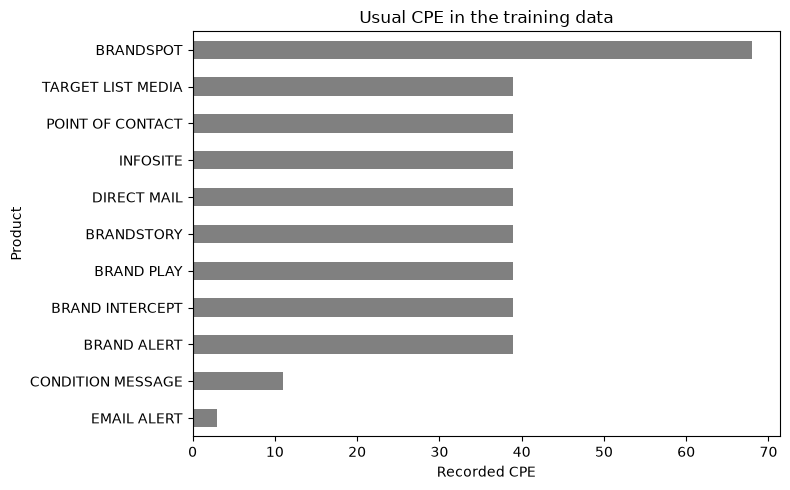

In [4]:
cpe_mapping["lookup_cpe"].sort_values().plot.barh(figsize=(8, 5), color="gray")
plt.xlabel("Recorded CPE")
plt.ylabel("Product")
plt.title("Usual CPE in the training data")
plt.tight_layout()
plt.show()

## 4. Predict CPE

The lookup uses the training median for each product. A product not seen in training gets the overall training median.

Linear regression gets only product type. Pandas turns each product into a column of zeros and ones. We use all product columns and no intercept, so each fitted coefficient is that product's training mean. This is a simple linear regression baseline.

We keep the CPE of 0.02 in Target List Media and the CPE of 11 in Condition Message. Their rarity is not enough evidence to call them errors. The 0.02 value changes the linear model's mean for Target List Media, but not its median lookup.

In [5]:
y_cpe_train = train["cpe"]
y_cpe_val = val["cpe"]

cpe_mean_pred = pd.Series(y_cpe_train.mean(), index=val.index)
cpe_lookup_pred = val["sub_product_name"].map(cpe_mapping["lookup_cpe"])
unseen_cpe = cpe_lookup_pred.isna()
cpe_lookup_pred = cpe_lookup_pred.fillna(y_cpe_train.median())

X_cpe_train = pd.get_dummies(train["sub_product_name"], dtype=int)
X_cpe_val = pd.get_dummies(val["sub_product_name"], dtype=int)
X_cpe_val = X_cpe_val.reindex(columns=X_cpe_train.columns, fill_value=0)

cpe_model = LinearRegression(fit_intercept=False)
cpe_model.fit(X_cpe_train, y_cpe_train)
cpe_linear_pred = pd.Series(cpe_model.predict(X_cpe_val), index=val.index)
cpe_linear_pred.loc[unseen_cpe] = y_cpe_train.median()
print("Validation rows with unseen products:", int(unseen_cpe.sum()))

cpe_predictions = pd.DataFrame({
    "training mean": cpe_mean_pred,
    "product lookup": cpe_lookup_pred,
    "linear regression": cpe_linear_pred
})
cpe_scores = []
for name in cpe_predictions:
    pred = cpe_predictions[name]
    cpe_scores.append({
        "model": name,
        "MAE": mean_absolute_error(y_cpe_val, pred),
        "R2": r2_score(y_cpe_val, pred)
    })
cpe_results = pd.DataFrame(cpe_scores).set_index("model")
cpe_results.round(6)

Validation rows with unseen products: 0


,MAE,R2
model,,
training mean,17.029887,-0.025551
product lookup,0.000000,1.000000
linear regression,0.118841,0.999446


In [6]:
lookup_error = (y_cpe_val - cpe_lookup_pred).abs()
print("Exact lookup matches:", int((lookup_error == 0).sum()), "of", len(val))
print("Largest lookup error:", lookup_error.max())
print("CPE values present in validation:", sorted(y_cpe_val.unique()))

cpe_errors = val[["company", "sub_product_name", "cpe"]].copy()
cpe_errors["lookup_prediction"] = cpe_lookup_pred
cpe_errors["linear_prediction"] = cpe_linear_pred
cpe_errors["linear_absolute_error"] = (y_cpe_val - cpe_linear_pred).abs()
cpe_errors.sort_values("linear_absolute_error", ascending=False).head()

Exact lookup matches: 82 of 82
Largest lookup error: 0.0
CPE values present in validation: [np.float64(3.0), np.float64(39.0), np.float64(68.0)]


,company,sub_product_name,cpe,lookup_prediction,linear_prediction,linear_absolute_error
10,ADC THERAPEUTICS,TARGET LIST MEDIA,39.0,39.0,37.375833,1.624167
402,TEVA,TARGET LIST MEDIA,39.0,39.0,37.375833,1.624167
19,ASTELLAS,TARGET LIST MEDIA,39.0,39.0,37.375833,1.624167
53,BRISTOL MYERS SQUIBB,TARGET LIST MEDIA,39.0,39.0,37.375833,1.624167
330,NOVO NORDISK,TARGET LIST MEDIA,39.0,39.0,37.375833,1.624167


## 5. What the CPE result means

The product lookup has zero error on all 82 validation rows. This is the zero-error result; the linear regression model has a small error because it keeps the unusual training value.

The training mapping is Email Alert = 3, BrandSpot = 68, Condition Message = 11, and 39 for the other listed products. Target List Media has one training exception at 0.02. Condition Message has only one training row, and its value of 11 is absent from validation.

We can easily map the recorded CPE in this validation sample. We have not proved that future prices will stay fixed, or that the mapping predicts actual future campaign efficiency. We also cannot establish from these numbers alone whether CPE is a quoted price or a measured cost.

## 6. Check total spend

Spend varies even when the company, product, and CPE are the same. This makes it a less trivial prediction target than recorded CPE.

The brief calls this column spend, but its units and time window are unconfirmed. It differs sharply from total_budget_spent. We therefore report results in recorded spend units, not dollars.

In [7]:
print("Different spend values:", df["total_spend"].nunique(), "across", len(df), "rows")
df.loc[
    (df["company"] == "ABBVIE") & (df["sub_product_name"] == "BRAND ALERT"),
    ["company", "sub_product_name", "campaign_start_date", "cpe", "total_spend", "total_budget_spent"]
].head(3)

Different spend values: 392 across 414 rows


,company,sub_product_name,campaign_start_date,cpe,total_spend,total_budget_spent
0,ABBVIE,BRAND ALERT,2024-07-31,39.0,134355308.0,173511.0
1,ABBVIE,BRAND ALERT,2024-08-19,39.0,10667850.0,45942.0
2,ABBVIE,BRAND ALERT,2023-11-16,39.0,59103000.0,66417.0


## 7. Choose inputs for spend

We use company, product type, country, specialty, region, and planned start year and month. We assume these describe choices available before the campaign. That assumption still needs confirmation.

We exclude spend, spend ratios, budget spent, engagements, reach, and prescription outcomes. We also exclude CPE because some values were calculated from campaign outcomes. Those columns could reveal information that would not be known before the campaign.

We derive the date inputs from the start date. Category lists come from training only. The first category is left out to serve as a reference. A category absent from training is treated like that reference; we count these cases below. This is a limitation of this simple baseline.

In [8]:
category_columns = ["company", "sub_product_name", "country", "npi_specialty", "region"]
X_spend_train = train[category_columns].copy()
X_spend_val = val[category_columns].copy()
unseen_counts = {}

for column in category_columns:
    categories = sorted(train[column].unique())
    unseen_counts[column] = int((~val[column].isin(categories)).sum())
    X_spend_train[column] = pd.Categorical(train[column], categories=categories)
    X_spend_val[column] = pd.Categorical(val[column], categories=categories)

X_spend_train["start_year"] = train["campaign_start_date"].dt.year
X_spend_train["start_month"] = train["campaign_start_date"].dt.month
X_spend_val["start_year"] = val["campaign_start_date"].dt.year
X_spend_val["start_month"] = val["campaign_start_date"].dt.month

X_spend_train = pd.get_dummies(X_spend_train, drop_first=True, dtype=int)
X_spend_val = pd.get_dummies(X_spend_val, drop_first=True, dtype=int)
X_spend_val = X_spend_val.reindex(columns=X_spend_train.columns, fill_value=0)

print("Input columns:", X_spend_train.shape[1])
print("Validation rows with a category absent from training:")
print(pd.Series(unseen_counts))
assert list(X_spend_train.columns) == list(X_spend_val.columns)
assert X_spend_train.isna().sum().sum() == 0
assert X_spend_val.isna().sum().sum() == 0

Input columns: 68
Validation rows with a category absent from training:
company             6
sub_product_name    0
country             0
npi_specialty       1
region              0
dtype: int64


## 8. Fit linear regression for spend

We fit ordinary linear regression directly to the recorded spend values. The comparison model predicts the training average for every validation row.

We keep any negative linear predictions in the results so we can see this model's limitations. Negative spend predictions would not be useful for planning.

In [9]:
y_spend_train = train["total_spend"]
y_spend_val = val["total_spend"]

spend_model = LinearRegression()
spend_model.fit(X_spend_train, y_spend_train)
spend_linear_pred = pd.Series(spend_model.predict(X_spend_val), index=val.index)
spend_mean_pred = pd.Series(y_spend_train.mean(), index=val.index)

spend_predictions = pd.DataFrame({
    "training mean": spend_mean_pred,
    "linear regression": spend_linear_pred
})
print("Negative linear predictions:", int((spend_linear_pred < 0).sum()))

Negative linear predictions: 20


## 9. Measure spend errors

MAE is the average absolute error, in recorded spend units. Lower is better. R2 compares squared errors with predicting the validation average. A negative R2 means the model does worse than that reference.

MAPE is the average absolute percentage error. It is undefined when actual spend is zero and can become very large near zero. We show MAPE for all positive targets, plus a separate view for targets of at least 1,000 recorded units. The 1,000 threshold follows the existing cleaning flag; it is not a confirmed business threshold. We report the row counts and never drop these rows from MAE or R2.

The brief's goals are MAPE below 30% and R2 above 0.55. Our split is not a confirmed H2 test, so these scores cannot establish that the H2 goals are met.

In [10]:
positive_spend = y_spend_val > 0
spend_at_least_1000 = y_spend_val >= 1000
print("Rows scored for MAE and R2:", len(val))
print("Rows scored for positive-spend MAPE:", int(positive_spend.sum()))
print("Rows scored for spend-at-least-1000 MAPE:", int(spend_at_least_1000.sum()))

spend_scores = []
for name in spend_predictions:
    pred = spend_predictions[name]
    absolute_error = (y_spend_val - pred).abs()
    mape_positive = (absolute_error[positive_spend] / y_spend_val[positive_spend]).mean() * 100
    mape_1000 = (absolute_error[spend_at_least_1000] / y_spend_val[spend_at_least_1000]).mean() * 100
    spend_scores.append({
        "model": name,
        "MAE": mean_absolute_error(y_spend_val, pred),
        "R2": r2_score(y_spend_val, pred),
        "MAPE positive (%)": mape_positive,
        "MAPE at least 1000 (%)": mape_1000
    })
spend_results = pd.DataFrame(spend_scores).set_index("model")
spend_results.round(3)

Rows scored for MAE and R2: 82
Rows scored for positive-spend MAPE: 81
Rows scored for spend-at-least-1000 MAPE: 80


,MAE,R2,MAPE positive (%),MAPE at least 1000 (%)
model,,,,
training mean,1.471931e+09,-0.278,1.872857e+09,6619.618
linear regression,2.239424e+09,-2.965,3.659233e+09,7073.000


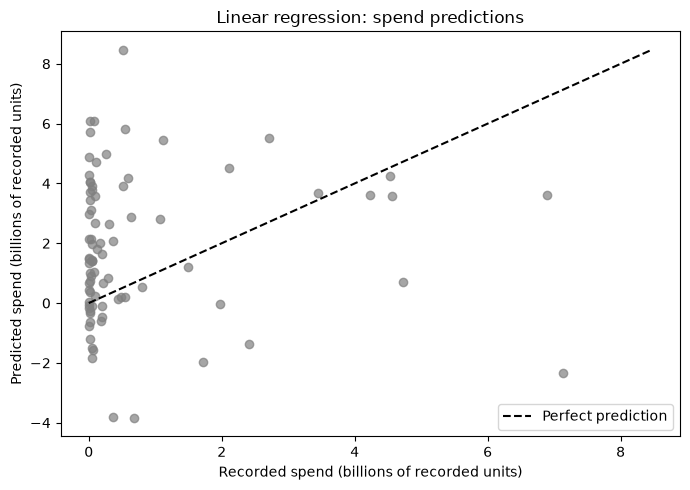

In [11]:
plt.figure(figsize=(7, 5))
plt.scatter(y_spend_val / 1e9, spend_linear_pred / 1e9, color="gray", alpha=0.7)
upper = max(y_spend_val.max(), spend_linear_pred.max()) / 1e9
plt.plot([0, upper], [0, upper], color="black", linestyle="--", label="Perfect prediction")
plt.xlabel("Recorded spend (billions of recorded units)")
plt.ylabel("Predicted spend (billions of recorded units)")
plt.title("Linear regression: spend predictions")
plt.legend()
plt.tight_layout()
plt.show()

In [12]:
spend_errors = val[["company", "sub_product_name", "campaign_start_date", "total_spend"]].copy()
spend_errors["predicted_spend"] = spend_linear_pred
spend_errors["absolute_error"] = (y_spend_val - spend_linear_pred).abs()
spend_errors.sort_values("absolute_error", ascending=False).head()

,company,sub_product_name,campaign_start_date,total_spend,predicted_spend,absolute_error
15,AMGEN,EMAIL ALERT,2025-03-31,7.130260e+09,-2.328930e+09,9.459189e+09
216,MERCK,BRAND ALERT,2025-12-15,5.190420e+08,8.469414e+09,7.950372e+09
145,JANSSEN,EMAIL ALERT,2025-11-10,1.180800e+07,6.080354e+09,6.068546e+09
267,MERCK,EMAIL ALERT,2025-12-23,7.181341e+07,6.090094e+09,6.018280e+09
212,MERCK,BRAND ALERT,2025-12-22,1.225800e+07,5.728258e+09,5.716000e+09


## 10. Conclusions

CPE is easy to map in this validation sample. The product-median lookup gets all 82 values exactly right. Linear regression is close, but its error is not zero when the unusual training row is retained. A zero-error lookup does not prove future campaign efficiency is predictable.

Total spend is a better candidate for further prediction work because it varies within product types. That is a reason to investigate it, not evidence that this baseline is accurate.

The spend linear model has MAE of about 2.239 billion recorded units and R2 of -2.965. Predicting the training average has lower MAE, about 1.472 billion. Linear regression also produces 20 negative predictions out of 82. This spend model does not improve on the simple average baseline and is not ready for planning.

The current model is a starting point. Spend units and outcome dates remain unconfirmed. We must not describe this as a finished H2 forecasting model.

For a fair comparison, the XGBoost owner needs the same 414-row source, the same date split, the same target values, and the same input columns for each target. CPE and spend scores must be compared separately. No other team notebooks or datasets were changed.